# rd2dnet tutorial

`rd2dnet` estimates boundary discontinuity designs on networks. It carries the
location-based framework of **rd2d** (Cattaneo, Titiunik and Yu) over from Euclidean
coordinates to network coordinates and user-defined network metrics: side-specific local
polynomials, robust bias-corrected inference, uniform bands, data-driven bandwidths and
aggregate effects. Please cite the rd2d papers (see the README) when you use it.

This notebook uses the bundled **mock city**, a small synthetic street grid with a
boundary along "60th Street" (treated side to the south), a highway with ramps, and a park
on the boundary. It is only an illustration; nothing here depends on that application.
Everything runs offline in about a minute.

Contents
1. Data and network
2. Distance is a metric you choose
3. Network coordinates
4. Estimation: bandwidths, BATEC curve, uniform band
5. Aggregate effects: WBATE and LBATE
6. Covariates, fuzzy designs, derivatives
7. Standard errors: cluster and Conley
8. Density (sorting) test
9. Recipes: donut, covariate balance, placebo boundary, difference-in-discontinuities
10. Large data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from shapely.geometry import LineString, box

import rd2dnet
from rd2dnet.datasets import load_mock_midtown, make_mock_midtown

city = load_mock_midtown()
obs = city.obs
y = obs["outcome"].to_numpy()
obs.head()

,x,y,treated,far,block,outcome
0,1592.404,863.317,True,11.762,6010,0.020990
1,102.434,52.888,True,1.990,0,-0.404383
2,2033.176,2920.818,False,4.258,8036,1.577470
3,1359.062,2992.232,False,4.078,5037,2.234262
4,2039.634,8.763,True,2.826,8000,-0.290319


## 1. Data and network

`city.graph` is a networkx graph whose nodes carry projected `x`/`y` coordinates (metres)
and whose edges carry `length`, `highway` class, `speed_kph` and `travel_time`.
`city.boundary` is a `rd2dnet.Boundary`: a line, the treated side, and a **mask** for the
park frontage, where one side has no parcels and no effect can be estimated.

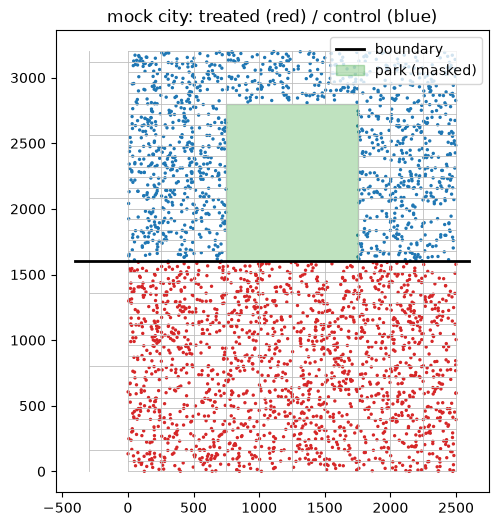

Boundary(length=3000.0, treated=region, masks=1)

In [2]:
fig, ax = plt.subplots(figsize=(7, 6))
for u, v in city.graph.edges():
    a, b = city.graph.nodes[u], city.graph.nodes[v]
    ax.plot([a["x"], b["x"]], [a["y"], b["y"]], color="0.75", lw=0.6)
ax.scatter(obs["x"], obs["y"], s=2, c=np.where(obs["treated"], "tab:red", "tab:blue"))
ax.plot(*city.boundary.line.xy, color="k", lw=2, label="boundary")
ax.fill(*city.park.exterior.xy, color="tab:green", alpha=0.3, label="park (masked)")
ax.set_aspect("equal"); ax.legend(loc="upper right"); ax.set_title("mock city: treated (red) / control (blue)")
plt.show()
city.boundary

## 2. Distance is a metric you choose

A `NetworkGraph` is a graph **plus a metric**. Distance means dissimilarity and does not
have to be metres. Coordinates, kernel distances and bandwidths are all in the metric's
units, while the treatment side stays geographic.

In [3]:
G = city.graph
metrics = {
    "length (m)": "length",
    "travel time (s)": rd2dnet.travel_time(),
    # 50 extra units per unit change in floor-area ratio between adjacent nodes
    "length + land-use contrast": rd2dnet.node_contrast("far", 50.0),
    # switching road class costs 500 m; ramps are transparent connectors, so
    # highway -> ramp -> highway is cheap but highway -> ramp -> street is not
    "length + class switches": rd2dnet.TransitionCost(
        "length", class_attr="highway", default_penalty=500.0, connectors={"motorway_link"}),
}
pts = obs[["x", "y"]].to_numpy()[:5]
pd.DataFrame({name: rd2dnet.network_coordinates(rd2dnet.NetworkGraph(G, m), city.boundary, pts, n_eval=5).s
              for name, m in metrics.items()}).round(1)

,length (m),travel time (s),length + land-use contrast,length + class switches
0,829.1,78.1,1487.1,829.1
1,1649.5,107.9,2190.1,1649.5
2,-1354.0,-118.9,-2327.9,-1354.0
3,-1783.2,-178.7,-2926.7,-2283.2
4,1648.4,149.7,3173.8,1648.4


Any node-by-node dissimilarity matrix works too (`Precomputed`). Observations then snap to
the nearest node, because per-edge costs are unknown.

In [4]:
base = rd2dnet.NetworkGraph(G, "length")
D = base.distances_from(np.arange(base.n_nodes))     # or your own matrix, in base.nodes order
pre = rd2dnet.NetworkGraph(G, rd2dnet.Precomputed(np.sqrt(D)))  # e.g. a concave transform
rd2dnet.network_coordinates(pre, city.boundary, pts, n_eval=5).s.round(2)

C:\rd_2d_network_expansion\rd2dnet\src\rd2dnet\coordinates.py:431: UserWarning: Precomputed(shape=(450, 450)) cannot split edges; make sure boundary nodes exist in the graph
  network = network.with_boundary_crossings(boundary)


array([ 26.83,  38.99, -36.88, -43.13,  40.  ])

## 3. Network coordinates

`network_coordinates` snaps each observation to the street network **on its own side**
and computes, as rd2d's `(X1 - b1, X2 - b2)`:

* `s`: signed network distance to the boundary (positive on the treated side);
* at each evaluation point `b`: `d(b)`, the network distance used for kernel weights, and
  `o(b)`, the signed offset along the boundary.

Evaluation points default to an even grid along the boundary; masked ones are skipped.

In [5]:
net = city.network("length")
coords = rd2dnet.network_coordinates(net, city.boundary, obs[["x", "y"]], n_eval=21)
print(coords)
coords.frame(j=10).head()

NetworkCoordinates(n=3000, treated=1764, eval_points=21, masked=7)


,x,y,treated,s,crossing_arc,depth,d,o
0,1592.404,863.317,True,829.087,1900.0,16.683,1229.087,400.0
1,102.434,52.888,True,1649.546,400.0,27.112,2544.678,-1100.0
2,2033.176,2920.818,False,-1353.994,2400.0,33.176,2253.994,900.0
3,1359.062,2992.232,False,-1783.170,2150.0,32.232,2351.294,650.0
4,2039.634,8.763,True,1648.397,2400.0,8.763,2548.397,900.0


In [6]:
coords.eval_table().head(8)

,arc,node,node_arc,x,y,masked
0,100.0,9060,100.0,-300.0,1600.0,False
1,240.0,9060,100.0,-300.0,1600.0,False
2,380.0,60,400.0,0.0,1600.0,False
3,520.0,60,520.0,120.0,1600.0,False
4,660.0,160,660.0,260.0,1600.0,False
5,800.0,260,800.0,400.0,1600.0,False
6,940.0,260,940.0,540.0,1600.0,False
7,1080.0,360,1080.0,680.0,1600.0,False


## 4. Estimation

`rdbwnet` ports rd2d's direct plug-in bandwidth selector (`mserd` by default; also
`msetwo`, `imserd`, `imsetwo` and the coverage-error-optimal `cer*` variants). `rdnet`
selects bandwidths itself when `h` is not given, fits order `p` (default 1) for the point
estimate and order `q = p + 1` for robust bias-corrected inference, and adds a uniform band.

In [7]:
bw = rd2dnet.rdbwnet(y, coords)
bw[["arc", "h0", "h1", "n0", "n1", "status"]].head()

,arc,h0,h1,n0,n1,status
0,100.0,NaN,NaN,NaN,NaN,singular
1,240.0,NaN,NaN,NaN,NaN,singular
2,380.0,880.614454,880.614454,1236.0,1764.0,ok
3,520.0,931.848632,931.848632,1236.0,1764.0,ok
4,660.0,725.897154,725.897154,1236.0,1764.0,ok


In [8]:
res = rd2dnet.rdnet(y, coords, seed=0)
print(res)

rd2dnet: network boundary discontinuity estimates (sharp)
  metric=EdgeCost('length')  kernel=triangular  p=1  q=2  vce=hc1
  evaluation points: 21  estimated: 12
  uniform band critical value: 2.739
     arc      h0      h1  n0  n1   tau    se  tau_bc  ci_lo  ci_hi  pvalue       status
 100.000     NaN     NaN   0   0   NaN   NaN     NaN    NaN    NaN     NaN no bandwidth
 240.000     NaN     NaN   0   0   NaN   NaN     NaN    NaN    NaN     NaN no bandwidth
 380.000 645.657 645.657  82 100 2.221 0.597   2.543  0.712  4.374   0.006           ok
 520.000 730.696 730.696 125 146 2.216 0.422   2.425  1.138  3.712   0.000           ok
 660.000 560.950 560.950 108 117 2.224 0.413   2.415  1.050  3.780   0.001           ok
 800.000 821.274 821.274 194 266 2.157 0.290   2.210  1.097  3.324   0.000           ok
 940.000 743.359 743.359 163 233 2.142 0.314   2.095  1.026  3.163   0.000           ok
1080.000 678.903 678.903  95 191 2.066 0.360   1.701  0.869  2.533   0.000           ok
1220.000

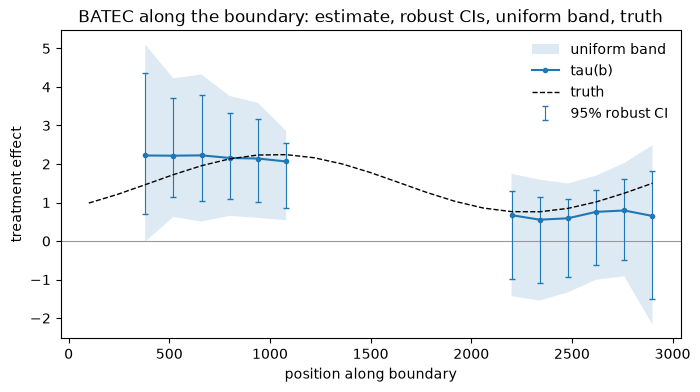

In [9]:
ax = res.plot(true_tau=city.true_tau(res.table["arc"]))
ax.set_title("BATEC along the boundary: estimate, robust CIs, uniform band, truth")
plt.show()

Bandwidths can also be given directly: a scalar, `(h_control, h_treated)`, one per
evaluation point, or a `(J, 2)` array. `weights=` multiplies the kernel weights (for
example floor area), and `pooled=True` fits a common-slope model.

In [10]:
res_fixed = rd2dnet.rdnet(y, coords, h=600.0, weights=obs["far"], seed=0)
res_fixed.table[["arc", "tau_bc", "se_rb", "status"]].head()

,arc,tau_bc,se_rb,status
0,100.0,NaN,NaN,insufficient
1,240.0,NaN,NaN,insufficient
2,380.0,2.464088,0.875367,ok
3,520.0,2.935654,0.562142,ok
4,660.0,2.722338,0.577378,ok


## 5. Aggregate effects: WBATE and LBATE

As in rd2d's `summary(WBATE=..., LBATE=True)`:

* **WBATE** `w' tau`: weights are normalised to sum to one, and the standard error
  `sqrt(w' Sigma w)` uses the joint covariance `res.cov` of the estimates across
  evaluation points. Points that were not estimated (masked) must get weight 0.
* **LBATE** `max_j tau(b_j)`: its interval uses the uniform critical value, so it
  inherits the band's joint coverage (conservative for the maximum).

In [11]:
ok = res.table["status"].eq("ok").to_numpy()
print(res.summary(wbate=ok.astype(float), lbate=True).split("aggregate effects")[1])

 (tau_bc and CI are bias-corrected):
        tau  tau_bc  se_rb  ci_lo  ci_hi  pvalue
WBATE 1.420   1.226  0.329  0.582  1.870   0.000
LBATE 2.224   2.543         0.654  5.102        


In [12]:
# Weight by frontage instead: here, by the number of parcels near each point.
w = np.where(ok, res.table["n0"] + res.table["n1"], 0.0)
res.wbate(w)

tau       1.445967
tau_bc    1.252609
se_rb     0.326544
ci_lo     0.612593
ci_hi     1.892624
pvalue    0.000125
Name: WBATE, dtype: float64

In [13]:
# Averaging correlated neighbours helps less than independence would suggest:
se_naive = np.sqrt(((ok / ok.sum()) ** 2 * res.table["se_rb"].fillna(0) ** 2).sum())
print(f"WBATE se with covariance {res.wbate(ok.astype(float))['se_rb']:.3f}  vs  ignoring it {se_naive:.3f}")

WBATE se with covariance 0.329  vs  ignoring it 0.182


## 6. Covariates, fuzzy designs, derivatives

**Covariates** enter with coefficients common to both sides (rd2d's `covs_eff`) and are
estimated jointly with the local polynomials. In the mock city the outcome depends only
weakly on log floor-area ratio (it explains about 1% of the noise), so adjusting for it
leaves estimates and standard errors almost unchanged. A covariate that predicts the
outcome well shrinks the standard errors.

In [14]:
res_cov = rd2dnet.rdnet(y, coords, h=600.0, covs=np.log(obs["far"]), seed=0)
res_raw = rd2dnet.rdnet(y, coords, h=600.0, seed=0)
pd.DataFrame({"tau_bc": res_raw.table["tau_bc"], "tau_bc (covs)": res_cov.table["tau_bc"],
              "se_rb": res_raw.table["se_rb"], "se_rb (covs)": res_cov.table["se_rb"]}).dropna().round(3).head()

,tau_bc,tau_bc (covs),se_rb,se_rb (covs)
2,2.563,2.579,0.954,0.973
3,2.671,2.670,0.664,0.669
4,2.339,2.338,0.660,0.662
5,2.314,2.296,0.780,0.773
6,1.849,1.836,0.650,0.648


**Fuzzy designs**: pass take-up `fuzzy=D`. The estimate is the ratio of the outcome jump
to the take-up jump at each point; the first stage is reported as `fs`/`fs_se`. Below,
take-up is 75% on the treated side and 25% on the other (true first stage 0.5) and the
effect of take-up is 2, in a larger simulated city (12,000 parcels). One draw scatters
around the truth, and neighbouring evaluation points move together because they share
observations; over 200 independent take-up draws the first stage averages 0.503, its
standard error matches the Monte Carlo spread, and 95% intervals cover 93% of the time.

In [15]:
big = make_mock_midtown(n_obs=12000, seed=11)
big_coords = rd2dnet.network_coordinates(big.network(), big.boundary, big.obs[["x", "y"]], n_eval=21)
rng = np.random.default_rng(2)
T = big_coords.treated
D_takeup = np.where(T, rng.uniform(size=len(T)) < 0.75, rng.uniform(size=len(T)) < 0.25).astype(float)
y_fuzzy = 0.0008 * (big.obs["y"] - 1600) + 2.0 * D_takeup + rng.normal(0, 0.5, len(T))
res_fz = rd2dnet.rdnet(y_fuzzy, big_coords, fuzzy=D_takeup, seed=0)
res_fz.table[["arc", "fs", "fs_se", "tau", "ci_lo", "ci_hi", "status"]].dropna().round(3).head()

,arc,fs,fs_se,tau,ci_lo,ci_hi,status
2,380.0,0.812,0.083,2.135,1.511,2.414,ok
3,520.0,0.717,0.056,2.113,1.732,2.353,ok
4,660.0,0.689,0.060,2.058,1.697,2.380,ok
5,800.0,0.578,0.056,2.037,1.568,2.198,ok
6,940.0,0.535,0.072,1.930,1.347,2.257,ok


**Derivatives**: `deriv=(1, 0)` is the jump in the slope *across* the boundary (a kink),
`deriv=(0, 1)` the jump in the slope *along* it, and `tangvec=(t_s, t_o)` any directional
derivative. The mock outcome has the same slope on both sides, so the true kink is zero
and the estimates sit near zero.

In [16]:
kink = rd2dnet.rdnet(y, coords, h=800.0, deriv=(1, 0), seed=0)
kink.table[["arc", "tau_bc", "ci_lo", "ci_hi", "status"]].dropna().round(5).head()

,arc,tau_bc,ci_lo,ci_hi,status
2,380.0,-0.00043,-0.00843,0.00757,ok
3,520.0,0.00100,-0.00621,0.00821,ok
4,660.0,-0.00005,-0.00592,0.00582,ok
5,800.0,0.00042,-0.00622,0.00706,ok
6,940.0,-0.00091,-0.00641,0.00459,ok


## 7. Standard errors

`vce` takes `hc0`-`hc3`; `cluster=` gives cluster-robust errors; `conley_cutoff=` gives a
Bartlett spatial HAC over **network** distance (or `conley_distance="euclidean"`). The
same choice drives the uniform band and WBATE/LBATE through `res.cov`.

A caution on `cluster=`: as in rd2d, cluster-robust errors use the residuals of the local
fit. When clusters are small relative to the bandwidth (here, city blocks inside a 600 m
window), the local polynomial absorbs much of the within-cluster variation and the
cluster standard errors come out too small, even with independent errors (see the
README's known limitations for a Monte Carlo). For spatially correlated shocks, the
Conley option, whose residuals come from a wider auxiliary fit, is the validated choice.

In [17]:
y_ = y
fits = {
    "HC1": rd2dnet.rdnet(y_, coords, h=600.0, seed=0),
    "cluster (block)": rd2dnet.rdnet(y_, coords, h=600.0, cluster=obs["block"], seed=0),
    "Conley 150 m (network)": rd2dnet.rdnet(y_, coords, h=600.0, conley_cutoff=150.0, seed=0),
    "Conley 150 m (Euclidean)": rd2dnet.rdnet(y_, coords, h=600.0, conley_cutoff=150.0,
                                              conley_distance="euclidean", seed=0),
}
pd.DataFrame({k: r.table["se_rb"] for k, r in fits.items()}).dropna().round(3).head()

,HC1,cluster (block),Conley 150 m (network),Conley 150 m (Euclidean)
2,0.954,0.322,0.898,0.749
3,0.664,0.431,0.660,0.602
4,0.660,0.455,0.528,0.449
5,0.780,0.454,0.621,0.491
6,0.650,0.446,0.512,0.404


## 8. Density (sorting) test

The local polynomial density test of Cattaneo, Jansson and Ma (`rddensity`). By default
position is measured in **cumulative street length** from the boundary
(`normalize="network"`), so the test asks whether there are more parcels per metre of
street on one side, instead of reacting to differences in street supply.

In [18]:
print(rd2dnet.density(coords))
print(rd2dnet.density(coords, normalize="none"))

rd2dnet density test (network): jump=-1.98e-07 (bc 3.37e-06) se=3.2e-06 z=1.053 p=0.2923 log-ratio=-0.020 [n=903/896, in window 241/272, h=12249.6/12249.6]
rd2dnet density test (none): jump=2.53e-05 (bc -5.15e-05) se=9.4e-05 z=-0.548 p=0.5834 log-ratio=0.643 [n=903/896, in window 136/144, h=326.8/326.8]


## 9. Recipes

These need no special API; they combine the pieces above.

### Donut
Drop observations within `delta` (in metric units) of the boundary. Missing outcomes are
skipped.

In [19]:
delta = 40.0
y_donut = np.where(np.abs(coords.s) < delta, np.nan, y)
donut = rd2dnet.rdnet(y_donut, coords, h=700.0, seed=0)
pd.DataFrame({"full": res_fixed.table["tau_bc"], "donut 40 m": donut.table["tau_bc"]}).dropna().round(3).head()

,full,donut 40 m
2,2.464,1.340
3,2.936,1.085
4,2.722,1.435
5,2.587,1.169
6,2.050,1.539


### Covariate balance
Pass a pre-determined characteristic as the outcome; there should be no jump. In the mock
city, floor-area ratio is unrelated to treatment.

In [20]:
bal = rd2dnet.rdnet(np.log(obs["far"]), coords, seed=0)
ok_b = bal.table["status"].eq("ok").to_numpy()
print(bal.summary(wbate=ok_b.astype(float), lbate=True).split("aggregate effects")[1])

 (tau_bc and CI are bias-corrected):
        tau  tau_bc  se_rb  ci_lo  ci_hi  pvalue
WBATE 0.006   0.062  0.150 -0.231  0.356   0.677
LBATE 0.106   0.243        -0.470  1.388        


### Placebo boundary
Build a `Boundary` along a fake line inside one side and use only that side's
observations. Here: a street 8 blocks north, on the control side. It runs through the
park, which is masked.

In [21]:
from rd2dnet.datasets import BOUNDARY_Y, PARK
fake_y = BOUNDARY_Y + 8 * 80.0
north = obs["y"].to_numpy() > BOUNDARY_Y
fake = rd2dnet.Boundary(LineString([(-400, fake_y), (2600, fake_y)]),
                        treated_region=box(-1e5, -1e5, 1e5, fake_y), mask=[PARK])
pc = rd2dnet.network_coordinates(city.network(), fake, obs.loc[north, ["x", "y"]], n_eval=15)
placebo = rd2dnet.rdnet(y[north], pc, seed=0)
ok_p = placebo.table["status"].eq("ok").to_numpy()
print(placebo.summary(wbate=ok_p.astype(float)).split("aggregate effects")[1])

 (tau_bc and CI are bias-corrected):
         tau  tau_bc  se_rb  ci_lo  ci_hi  pvalue
WBATE -0.004   0.126  0.286 -0.435  0.687   0.661


### Difference-in-discontinuities
With a **panel** (the same units before and after), run on `y_post - y_pre`. With
**independent samples**, estimate each period with the same evaluation points and
bandwidths and difference the estimates, with `se = sqrt(se_pre**2 + se_post**2)`.
Overlapping but non-identical samples would need the cross-period covariance, which rd2d
does not provide either.

In [22]:
rng = np.random.default_rng(5)
f = y - city.true_tau(coords.crossing_arc) * coords.treated           # outcome without the effect
y_pre = f + rng.normal(0, 0.5, len(y))                               # same parcels, earlier period
y_post = y + rng.normal(0, 0.5, len(y))
did_panel = rd2dnet.rdnet(y_post - y_pre, coords, h=700.0, seed=0)

# independent samples: two cross-sections with the same evaluation points and bandwidth
c_pre, c_post = make_mock_midtown(n_obs=3000, seed=21), make_mock_midtown(n_obs=3000, seed=22)
co_pre = rd2dnet.network_coordinates(c_pre.network(), c_pre.boundary, c_pre.obs[["x", "y"]], n_eval=21)
co_post = rd2dnet.network_coordinates(c_post.network(), c_post.boundary, c_post.obs[["x", "y"]], n_eval=21)
y0 = c_pre.obs["outcome"] - c_pre.true_tau(co_pre.crossing_arc) * co_pre.treated
r_pre = rd2dnet.rdnet(y0, co_pre, h=700.0, seed=0).table
r_post = rd2dnet.rdnet(c_post.obs["outcome"], co_post, h=700.0, seed=0).table
did = pd.DataFrame({"arc": r_post["arc"],
                    "panel": did_panel.table["tau_bc"],
                    "independent": r_post["tau_bc"] - r_pre["tau_bc"],
                    "se (independent)": np.sqrt(r_pre["se_rb"] ** 2 + r_post["se_rb"] ** 2),
                    "truth": city.true_tau(r_post["arc"])})
did.dropna().round(3).head()

,arc,panel,independent,se (independent),truth
2,380.0,2.215,0.178,1.039,1.462
3,520.0,1.931,0.886,0.645,1.723
4,660.0,1.901,1.968,0.492,1.956
5,800.0,1.965,2.468,0.467,2.133
6,940.0,2.083,2.979,0.518,2.233


## 10. Large data

* **Repeated measurements** (sensor panels, many readings per site) are snapped and
  measured once per distinct location: `coords.n_locations` vs `coords.n_obs`.
* Snapping, boundary geometry, the Conley kernel and bandwidth selection use several
  threads; set the environment variable `RD2DNET_NUM_THREADS` to cap them (`1` disables).
* Conley cost grows with the number of observation pairs closer than the cutoff, which
  grows with the square of local density. With millions of nearby points, a smaller cutoff
  or clustered errors are much cheaper.
* `benchmarks/profile_scale.py` times every stage on synthetic city, suburb and river
  networks with up to millions of observations; see the README's Scale section.

In [23]:
panel_xy = np.repeat(obs[["x", "y"]].to_numpy()[:500], 20, axis=0)    # 500 sensors x 20 readings
pcoords = rd2dnet.network_coordinates(net, city.boundary, panel_xy, n_eval=11)
pcoords.n_obs, pcoords.n_locations

(10000, 500)